# Member 4 — Features and Imbalance

**Project:** Hotel Booking Demand — Cancellation Risk  
**Owner:** IT24104068 (Member 4)

Purpose: Engineer new features and address target class imbalance.


## Cell 1 — Load training data

In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

data_path = Path("../../data/processed/hotel_bookings_validated_phase3.csv")
split_path = Path("../../results/splits/group_holdout_indices.npz")

df = pd.read_csv(data_path)
splits = np.load(split_path)

excluded = [
    "is_canceled", "assigned_room_type", "booking_changes",
    "deposit_type", "agent", "company", "adr",
    "required_car_parking_spaces", "total_of_special_requests",
    "reservation_status", "reservation_status_date"
]

X = df.drop(columns=excluded)
y = df["is_canceled"]

X_train = X.iloc[splits["train_idx"]].copy()
y_train = y.iloc[splits["train_idx"]].copy()

print("Training data:", X_train.shape)
print("Training cancellation rate:", f"{y_train.mean():.2%}")


Training data: (95334, 21)
Training cancellation rate: 37.01%


## Cell 2 — Check class imbalance

Class distribution:
is_canceled
0    60053
1    35281
Name: count, dtype: int64

Percentage:
is_canceled
0    62.99
1    37.01
Name: count, dtype: float64


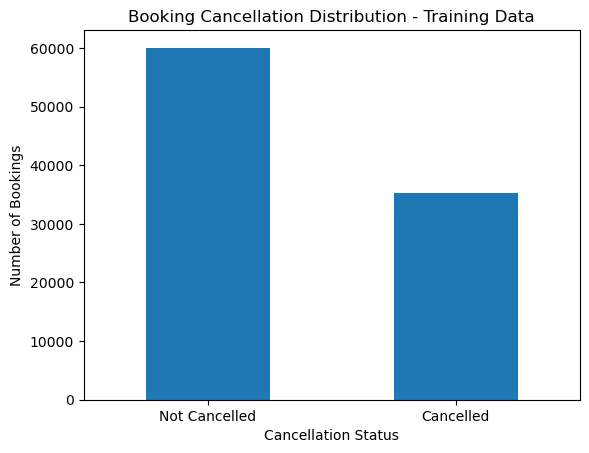

In [2]:

import matplotlib.pyplot as plt

counts = y_train.value_counts().sort_index()

print("Class distribution:")
print(counts)

print("\nPercentage:")
print((counts / len(y_train) * 100).round(2))

counts.plot(kind="bar")
plt.title("Booking Cancellation Distribution - Training Data")
plt.xlabel("Cancellation Status")
plt.ylabel("Number of Bookings")
plt.xticks([0, 1], ["Not Cancelled", "Cancelled"], rotation=0)
plt.show()


## Cell 3 — Create two useful features

In [3]:

X_train_fe = X_train.copy()

X_train_fe["total_nights"] = (
    X_train_fe["stays_in_weekend_nights"] +
    X_train_fe["stays_in_week_nights"]
)

X_train_fe["total_guests"] = (
    X_train_fe["adults"] +
    X_train_fe["children"] +
    X_train_fe["babies"]
)

print("Original features:", X_train.shape[1])
print("Features after engineering:", X_train_fe.shape[1])

display(X_train_fe[[
    "total_nights",
    "total_guests"
]].describe())


Original features: 21
Features after engineering: 23


,total_nights,total_guests
count,95334.000000,95334.000000
mean,3.422022,1.968836
std,2.527343,0.725311
min,0.000000,1.000000
25%,2.000000,2.000000
50%,3.000000,2.000000
75%,4.000000,2.000000
max,69.000000,55.000000


## Cell 4 — Check feature redundancy

In [4]:

columns = [
    "total_nights",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "total_guests",
    "adults",
    "children",
    "babies"
]

correlation = X_train_fe[columns].corr()

display(correlation.round(2))


,total_nights,stays_in_weekend_nights,stays_in_week_nights,total_guests,adults,children,babies
total_nights,1.00,0.76,0.94,0.12,0.11,0.05,0.02
stays_in_weekend_nights,0.76,1.00,0.49,0.10,0.09,0.04,0.02
stays_in_week_nights,0.94,0.49,1.00,0.10,0.10,0.04,0.02
total_guests,0.12,0.10,0.10,1.00,0.82,0.57,0.16
adults,0.11,0.09,0.10,0.82,1.00,0.03,0.02
children,0.05,0.04,0.04,0.57,0.03,1.00,0.02
babies,0.02,0.02,0.02,0.16,0.02,0.02,1.00


In [5]:

# Check unusual booking values
zero_nights = (X_train_fe["total_nights"] == 0)
long_stays = (X_train_fe["total_nights"] > 30)
large_groups = (X_train_fe["total_guests"] > 10)

print("Zero-night bookings:", zero_nights.sum())
print("Bookings over 30 nights:", long_stays.sum())
print("Bookings over 10 guests:", large_groups.sum())

# Examine a few unusual records
unusual = X_train_fe[
    zero_nights | long_stays | large_groups
]

display(unusual[[
    "total_nights", "total_guests",
    "adults", "children", "babies"
]].sort_values(
    "total_guests", ascending=False
).head(10))


Zero-night bookings: 502
Bookings over 30 nights: 18
Bookings over 10 guests: 11


,total_nights,total_guests,adults,children,babies
2173,2,55.0,55,0.0,0
1643,3,50.0,50,0.0,0
1539,3,40.0,40,0.0,0
1917,4,27.0,27,0.0,0
1962,4,27.0,27,0.0,0
1587,7,26.0,26,0.0,0
2003,7,26.0,26,0.0,0
1884,7,26.0,26,0.0,0
2416,7,20.0,20,0.0,0
46598,2,12.0,2,0.0,10


### Final Findings and Decisions

The training dataset contains 60,053 non-cancelled bookings (62.99%) and 35,281 cancelled bookings (37.01%). The class distribution was retained without resampling for the initial models.

Two candidate features, `total_nights` and `total_guests`, were constructed. Both are derived from existing attributes and showed strong correlations with some of their original components. Their predictive usefulness will be evaluated later.

Additional checks identified 502 zero-night bookings, 18 stays exceeding 30 nights, and 11 bookings involving more than 10 guests. These observations were retained because their validity could not be conclusively determined.

The initial model configuration will use the original 21 approved features. The engineered features and imbalance-handling alternatives will be assessed using training-only validation.